# Notebook 11 — Object Detection with PyTorch
### Complete Practical Project · Faster R-CNN · Penn-Fudan Pedestrian Dataset

**Goal:** build, train, evaluate, visualize, save, reload, and use a real object-detection model.

This notebook is intentionally self-contained: explanations, equations, code, plots, evaluation, exercises, and references all live in this one notebook.

**Model:** Faster R-CNN with ResNet-50 FPN  
**Dataset:** Penn-Fudan Pedestrian  
**Classes:** background (0), pedestrian (1)

> Hardware: detection is memory-intensive. The defaults use a small batch and a short training run. On a 4 GB GPU, reduce batch size to 1 and image size if necessary. CPU execution is supported but can be slow.


## Learning roadmap

1. Environment and reproducibility
2. Object detection problem definition
3. Bounding-box geometry
4. IoU, GIoU, DIoU, and CIoU
5. Penn-Fudan download and exploration
6. Instance masks to bounding boxes
7. Custom Dataset and DataLoader
8. Visualization and train/validation split
9. Data augmentation
10. Faster R-CNN architecture
11. Anchors and Region Proposal Network
12. RoI Align and detection heads
13. Loss functions and optimization
14. Training pipeline
15. Precision, recall, AP, and mAP
16. NMS and prediction visualization
17. Error analysis
18. Saving, loading, and inference
19. Exercises and references


## 1. Environment and reproducibility

Install compatible PyTorch and TorchVision builds for your CUDA version if needed. The official installation selector is https://pytorch.org/get-started/locally/.

In [2]:
# Uncomment only if dependencies are missing:
# %pip install torch torchvision matplotlib numpy pillow tqdm

import os, random, time, math, zipfile, urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from tqdm.auto import tqdm

import torch
import torchvision
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms as T
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou, nms

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.5.1+cu121
TorchVision: 0.20.1+cu121
CUDA available: True


In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

BATCH_SIZE = 1 if DEVICE.type == "cuda" else 2
NUM_EPOCHS = 5
LEARNING_RATE = 0.005
NUM_WORKERS = 0
SCORE_THRESHOLD = 0.50
IOU_THRESHOLD = 0.50

print("Device:", DEVICE, "| Batch size:", BATCH_SIZE)


Device: cuda | Batch size: 1


## 2. Object detection: problem definition

Image classification assigns a label to an entire image. Object detection predicts both the class and spatial location of each object.

For an input image \(I\), a detector predicts a set:

\[
f_\theta(I)=\{(b_i,c_i,s_i)\}_{i=1}^{N}
\]

where \(b_i=(x_{\min},y_{\min},x_{\max},y_{\max})\) is a bounding box, \(c_i\) is a class label, \(s_i\in[0,1]\) is a confidence score, and \(N\) is the number of retained detections.

| Task | Prediction |
|---|---|
| Image classification | Class of the whole image |
| Object localization | Class and location of a main object |
| Object detection | Class and location of multiple objects |

TorchVision detection models reserve label `0` for background. Here, pedestrian is label `1`.

## 3. Bounding-box mathematics

We use corner coordinates:

$$
b=(x_{\min},y_{\min},x_{\max},y_{\max})
$$

$$
w=x_{\max}-x_{\min},\qquad h=y_{\max}-y_{\min}
$$

$$
A(b)=wh
$$

For an image of width $W$ and height $H$, a valid box satisfies:

$$
0\leq x_{\min}<x_{\max}\leq W
$$

$$
0\leq y_{\min}<y_{\max}\leq H
$$

The origin is the top-left pixel. The right and bottom coordinates are exclusive in the convention used by this notebook.

In [5]:
def box_area(boxes):
    wh = (boxes[:, 2:] - boxes[:, :2]).clamp(min=0)
    return wh[:, 0] * wh[:, 1]


def validate_boxes(boxes, width, height):
    if boxes.numel() == 0:
        return True
    return bool(
        torch.isfinite(boxes).all()
        and (boxes[:, 0] >= 0).all() and (boxes[:, 1] >= 0).all()
        and (boxes[:, 2] <= width).all() and (boxes[:, 3] <= height).all()
        and (boxes[:, 2] > boxes[:, 0]).all()
        and (boxes[:, 3] > boxes[:, 1]).all()
    )


## 4. Intersection over Union (IoU)

IoU quantifies the overlap between a predicted box $B_p$ and a ground-truth box $B_{gt}$:

$$
IoU(B_p,B_{gt})=\frac{|B_p\cap B_{gt}|}{|B_p\cup B_{gt}|}
$$

$$
|B_p\cup B_{gt}|=|B_p|+|B_{gt}|-|B_p\cap B_{gt}|
$$

IoU lies between 0 and 1. A larger value means stronger overlap.

In [6]:
def calculate_iou(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    intersection = max(0, ix2-ix1) * max(0, iy2-iy1)
    area_a = max(0, ax2-ax1) * max(0, ay2-ay1)
    area_b = max(0, bx2-bx1) * max(0, by2-by1)
    union = area_a + area_b - intersection
    return intersection / union if union else 0.0

box_a = [10, 10, 50, 60]
box_b = [30, 20, 70, 70]
print("IoU:", round(calculate_iou(box_a, box_b), 4))


IoU: 0.25


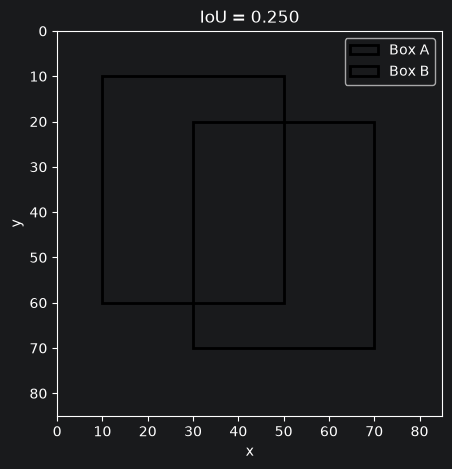

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.add_patch(Rectangle((10, 10), 40, 50, fill=False, linewidth=2, label="Box A"))
ax.add_patch(Rectangle((30, 20), 40, 50, fill=False, linewidth=2, label="Box B"))
ax.set_xlim(0, 85); ax.set_ylim(85, 0); ax.set_aspect("equal")
ax.set_title(f"IoU = {calculate_iou(box_a, box_b):.3f}")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(); plt.show()


### Generalized IoU and related metrics

IoU-based losses can be uninformative when boxes do not overlap. Generalized IoU adds a penalty using the smallest enclosing box $C$:

$$
GIoU=IoU-\frac{|C\setminus(B_p\cup B_{gt})|}{|C|}
$$

Distance-IoU (DIoU) additionally penalizes the normalized distance between box centers. Complete-IoU (CIoU) also accounts for aspect-ratio consistency. These are important alternatives in modern detection research; the standard TorchVision Faster R-CNN box-regression loss is not a GIoU/DIoU/CIoU loss.

## 5. Penn-Fudan dataset: download and exploration

Penn-Fudan is a small pedestrian dataset containing RGB images and instance masks. Each non-zero mask value identifies an individual pedestrian. We derive one bounding box per instance.

Dataset source used by the PyTorch tutorial: https://www.cis.upenn.edu/~jshi/ped_html/

In [11]:
import urllib.request
import ssl
import certifi
import zipfile

DATA_ROOT.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DATA_ROOT / "PennFudanPed.zip"
DATA_DIR = DATA_ROOT / "PennFudanPed"
DATA_URL = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"

if not DATA_DIR.exists():
    if not ZIP_PATH.exists():
        print("Downloading Penn-Fudan...")

        ssl_context = ssl.create_default_context(
            cafile=certifi.where()
        )

        with urllib.request.urlopen(
            DATA_URL,
            context=ssl_context,
            timeout=120
        ) as response:
            ZIP_PATH.write_bytes(response.read())

        print("Download completed.")

    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(DATA_ROOT)

    print("Extraction completed.")

assert (DATA_DIR / "PNGImages").exists(), \
    "Dataset extraction failed; inspect the archive structure."

image_paths = sorted(
    (DATA_DIR / "PNGImages").glob("*.png")
)

mask_paths = sorted(
    (DATA_DIR / "PedMasks").glob("*_mask.png")
)

print("Images:", len(image_paths), "| Masks:", len(mask_paths))

Download completed.
Extracting dataset...
Extraction completed.
Images: 170 | Masks: 170


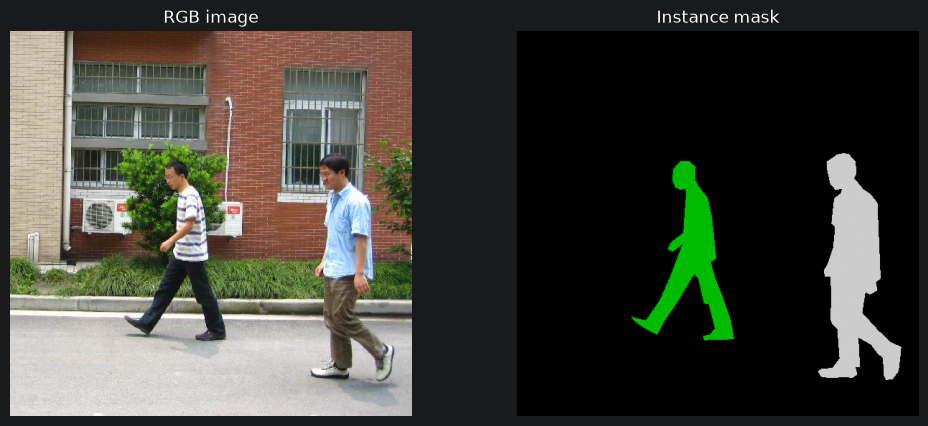

In [12]:
sample_image = Image.open(image_paths[0]).convert("RGB")
sample_mask = Image.open(mask_paths[0])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(sample_image); axes[0].set_title("RGB image"); axes[0].axis("off")
axes[1].imshow(sample_mask, cmap="nipy_spectral"); axes[1].set_title("Instance mask"); axes[1].axis("off")
plt.show()


## 6. Convert instance masks to bounding boxes

For each instance ID $k$, find the pixel coordinates belonging to that instance:

$$
x_{\min}=\min(x),\quad x_{\max}=\max(x)+1
$$

$$
y_{\min}=\min(y),\quad y_{\max}=\max(y)+1
$$

The $+1$ produces exclusive right/bottom coordinates.

In [13]:
def mask_to_boxes(mask_image):
    mask = np.asarray(mask_image)
    instance_ids = np.unique(mask)
    instance_ids = instance_ids[instance_ids != 0]
    boxes = []
    for instance_id in instance_ids:
        ys, xs = np.where(mask == instance_id)
        if len(xs):
            x1, x2 = xs.min(), xs.max() + 1
            y1, y2 = ys.min(), ys.max() + 1
            if x2 > x1 and y2 > y1:
                boxes.append([x1, y1, x2, y2])
    boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)
    labels = torch.ones((len(boxes),), dtype=torch.int64)
    return boxes, labels

sample_boxes, sample_labels = mask_to_boxes(sample_mask)
print("Boxes:", sample_boxes)
print("Labels:", sample_labels)
print("Valid:", validate_boxes(sample_boxes, sample_image.width, sample_image.height))


Boxes: tensor([[159., 181., 302., 431.],
        [419., 170., 535., 486.]])
Labels: tensor([1, 1])
Valid: True


## 7. Custom PyTorch Dataset and DataLoader

TorchVision detection models expect each image as a tensor `[C,H,W]`. Each target is a dictionary with at least `boxes` (float32 `[N,4]`) and `labels` (int64 `[N]`). We also include `image_id`, `area`, and `iscrowd`.

In [14]:
class PennFudanDataset(Dataset):
    def __init__(self, root, transform=None):
        self.root = Path(root)
        self.transform = transform
        image_dir = self.root / "PNGImages"
        mask_dir = self.root / "PedMasks"
        images = sorted(image_dir.glob("*.png"))
        masks = {p.name.replace("_mask", ""): p for p in mask_dir.glob("*_mask.png")}
        self.samples = [(p, masks[p.name]) for p in images if p.name in masks]
        if not self.samples:
            raise RuntimeError("No matching image/mask pairs found.")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, mask_path = self.samples[idx]
        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path)
        boxes, labels = mask_to_boxes(mask)
        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx], dtype=torch.int64),
            "area": box_area(boxes),
            "iscrowd": torch.zeros((len(boxes),), dtype=torch.int64),
        }
        if self.transform:
            image = self.transform(image)
        return image, target


def detection_collate_fn(batch):
    return tuple(zip(*batch))


dataset = PennFudanDataset(DATA_DIR, transform=T.ToTensor())
print("Samples:", len(dataset))
img0, target0 = dataset[0]
print("Image:", img0.shape, "| boxes:", target0["boxes"].shape)


Samples: 170
Image: torch.Size([3, 536, 559]) | boxes: torch.Size([2, 4])


## 8. Annotation visualization and data split

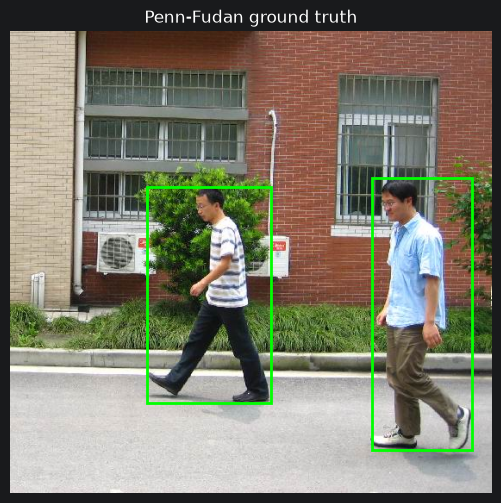

Train: 136 | Validation: 34


In [15]:
def show_boxes(image, boxes, title="Bounding boxes"):
    array = image.permute(1, 2, 0).cpu().numpy() if isinstance(image, torch.Tensor) else np.asarray(image)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(array)
    for box in boxes:
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                               edgecolor="lime", linewidth=2))
    ax.set_title(title); ax.axis("off"); plt.show()

show_boxes(img0, target0["boxes"], "Penn-Fudan ground truth")

n_val = max(1, int(0.20 * len(dataset)))
n_train = len(dataset) - n_val
train_set, val_set = random_split(
    dataset, [n_train, n_val], generator=torch.Generator().manual_seed(SEED)
)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, collate_fn=detection_collate_fn)
val_loader = DataLoader(val_set, batch_size=1, shuffle=False,
                        num_workers=NUM_WORKERS, collate_fn=detection_collate_fn)
print("Train:", len(train_set), "| Validation:", len(val_set))


## 9. Data augmentation

A horizontal flip must transform both the image and its boxes. For image width $W$:

$$
x'_{\min}=W-x_{\max},\qquad x'_{\max}=W-x_{\min}
$$

This wrapper applies a random horizontal flip without changing labels or instance counts.

In [16]:
class RandomHorizontalFlipDetection(Dataset):
    def __init__(self, subset, probability=0.5):
        self.subset = subset
        self.probability = probability

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, target = self.subset[idx]
        if random.random() < self.probability:
            width = image.shape[-1]
            image = torch.flip(image, dims=[2])
            boxes = target["boxes"].clone()
            if len(boxes):
                x_min = boxes[:, 0].clone()
                x_max = boxes[:, 2].clone()
                boxes[:, 0] = width - x_max
                boxes[:, 2] = width - x_min
            target = {**target, "boxes": boxes, "area": box_area(boxes)}
        return image, target

augmented_train_set = RandomHorizontalFlipDetection(train_set, 0.5)
train_loader = DataLoader(augmented_train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, collate_fn=detection_collate_fn)


## 10. Faster R-CNN architecture

Faster R-CNN is a two-stage detector:

1. **Backbone + FPN:** extracts multi-scale feature maps.
2. **Region Proposal Network (RPN):** proposes candidate object regions.
3. **RoI feature extraction:** maps each proposal to a fixed-size representation.
4. **Detection head:** predicts class scores and refined boxes.

\[
I\rightarrow\text{ResNet-FPN}\rightarrow\text{RPN}
\rightarrow\text{RoI Heads}\rightarrow\{b_i,c_i,s_i\}
\]

FPN combines feature maps at different resolutions, helping the detector handle objects at different scales.

In [18]:
from pathlib import Path
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

WEIGHTS_PATH = (
    Path.home()
    / ".cache/torch/hub/checkpoints/"
    / "fasterrcnn_resnet50_fpn_coco-258fb6c6.pth"
)

try:
    weights = torchvision.models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT

    if WEIGHTS_PATH.exists():
        print("Loading pretrained weights from local cache...")
        model = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None)
        state_dict = torch.load(
            WEIGHTS_PATH,
            map_location="cpu",
            weights_only=True
        )
        model.load_state_dict(state_dict)
    else:
        print("Downloading pretrained COCO weights...")
        model = fasterrcnn_resnet50_fpn(weights=weights)

    print("Pretrained COCO weights loaded successfully.")

except Exception as error:
    print("Could not load pretrained weights:", error)
    print("Using randomly initialized weights.")

    model = fasterrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None
    )

# Replace the detection head for 2 classes:
# Background + Pedestrian
in_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes=2
)

model.to(DEVICE)

print("Model ready:", DEVICE)
print("Number of classes:", 2)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\mobin/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
100%|██████████| 160M/160M [00:17<00:00, 9.63MB/s] 


Pretrained COCO weights loaded successfully.
Model ready: cuda
Number of classes: 2


## 11. Anchor boxes and Region Proposal Network

The RPN evaluates anchor boxes at multiple locations, scales, and aspect ratios. It predicts objectness and box offsets.

For an anchor $(x_a,y_a,w_a,h_a)$ and target box $(x,y,w,h)$, a common parameterization is:

$$
t_x=\frac{x-x_a}{w_a},\quad t_y=\frac{y-y_a}{h_a}
$$

$$
t_w=\log\frac{w}{w_a},\quad t_h=\log\frac{h}{h_a}
$$

The RPN learns offsets that transform anchors into candidate proposals.

In [19]:
print("Anchor sizes:", model.rpn.anchor_generator.sizes)
print("Anchor aspect ratios:", model.rpn.anchor_generator.aspect_ratios)
print("RoI output size:", model.roi_heads.box_roi_pool.output_size)


Anchor sizes: ((32,), (64,), (128,), (256,), (512,))
Anchor aspect ratios: ((0.5, 1.0, 2.0), (0.5, 1.0, 2.0), (0.5, 1.0, 2.0), (0.5, 1.0, 2.0), (0.5, 1.0, 2.0))
RoI output size: (7, 7)


## 12. RoI Align and detection heads

The RPN proposals can have different spatial sizes. RoI Align extracts a fixed-size feature representation while avoiding the coordinate quantization associated with traditional RoI Pooling. The detection head predicts class probabilities and box refinements.

TorchVision performs confidence filtering and NMS as part of the detector's post-processing.

## 13. Loss functions and optimization

Faster R-CNN returns four loss terms:

$$
L_{\mathrm{total}}=
L_{\mathrm{RPN-objectness}}+
L_{\mathrm{RPN-box}}+
L_{\mathrm{classifier}}+
L_{\mathrm{box-regression}}
$$

- **RPN objectness:** foreground/background proposal classification.
- **RPN box regression:** proposal coordinate refinement.
- **Classifier:** class prediction for sampled RoIs.
- **Box regression:** final bounding-box refinement.

Training minimizes the sum over training examples:

$$
\theta^*=\arg\min_\theta \frac{1}{N}\sum_{i=1}^{N}L_i(\theta)
$$

The exact internal target assignment and sampling are implemented by TorchVision.

In [21]:
optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

## 14. Training pipeline

During training, the model receives a list of images and a matching list of target dictionaries. It returns a dictionary of losses. We log each loss component by epoch.

For detection models, `model.train()` returns losses when targets are provided. In `model.eval()`, the model returns predictions instead. The validation section therefore evaluates predictions with detection metrics rather than treating evaluation-mode output as a loss dictionary.

In [22]:
def train_one_epoch(model, optimizer, loader, device, scaler):
    model.train()
    totals = {}
    batches = 0
    for images, targets in tqdm(loader, desc="Training", leave=False):
        images = [x.to(device) for x in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        optimizer.zero_grad(set_to_none=True)

        amp_enabled = device.type == "cuda"
        with torch.autocast(device_type=device.type, enabled=amp_enabled):
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())

        if not torch.isfinite(loss):
            print("Skipping non-finite loss batch.")
            continue

        if amp_enabled:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        for name, value in loss_dict.items():
            totals[name] = totals.get(name, 0.0) + float(value.detach().cpu())
        totals["total"] = totals.get("total", 0.0) + float(loss.detach().cpu())
        batches += 1

    return {k: v / max(batches, 1) for k, v in totals.items()}


history = []
best_loss = float("inf")
for epoch in range(NUM_EPOCHS):
    start = time.time()
    stats = train_one_epoch(model, optimizer, train_loader, DEVICE, scaler)
    scheduler.step()
    stats["epoch"] = epoch + 1
    stats["seconds"] = time.time() - start
    history.append(stats)
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | total loss={stats.get('total', float('nan')):.4f}")
    if stats.get("total", float("inf")) < best_loss:
        best_loss = stats["total"]
        torch.save(model.state_dict(), OUTPUT_DIR / "fasterrcnn_best_weights.pth")
print("Training finished.")


Training:  40%|████      | 55/136 [01:40<02:06,  1.57s/it]

Skipping non-finite loss batch.


Training:  57%|█████▋    | 77/136 [02:18<01:29,  1.52s/it]

Skipping non-finite loss batch.


Training:  63%|██████▎   | 86/136 [02:33<01:14,  1.49s/it]

...

Training:  94%|█████████▍| 128/136 [03:47<00:11,  1.44s/it]

Skipping non-finite loss batch.


Training:  98%|█████████▊| 133/136 [03:55<00:04,  1.42s/it]

Skipping non-finite loss batch.


Epoch 5/5 | total loss=0.0615
Training finished.


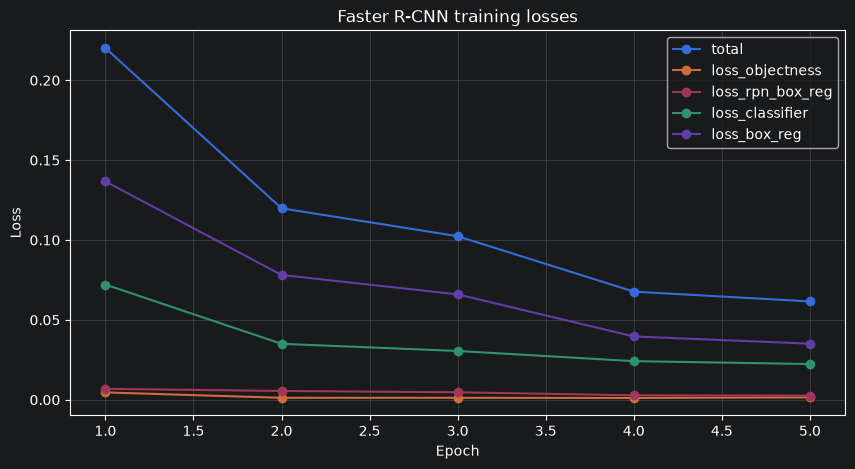

In [23]:
if history:
    epochs = [row["epoch"] for row in history]
    plt.figure(figsize=(10, 5))
    for key in ["total", "loss_objectness", "loss_rpn_box_reg",
                "loss_classifier", "loss_box_reg"]:
        values = [row.get(key, np.nan) for row in history]
        if np.isfinite(values).any():
            plt.plot(epochs, values, marker="o", label=key)
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.title("Faster R-CNN training losses")
    plt.grid(alpha=0.3); plt.legend(); plt.show()


## 15. Evaluation: precision, recall, AP, and mAP

For a chosen class and IoU threshold, detections are sorted by confidence and matched to ground-truth boxes. Each ground-truth box can be matched once.

$$
Precision=\frac{TP}{TP+FP},\qquad Recall=\frac{TP}{TP+FN}
$$

Average Precision (AP) summarizes the precision-recall curve. Mean Average Precision (mAP) averages AP across classes. COCO-style mAP averages AP over IoU thresholds $$(0.50,0.55,\ldots,0.95$$).

The next implementation calculates **single-class interpolated AP at one IoU threshold**. It is intended for teaching, not as a replacement for the official COCO evaluator.

In [24]:
@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    predictions, targets = [], []
    for images, target_batch in tqdm(loader, desc="Evaluation", leave=False):
        outputs = model([im.to(device) for im in images])
        predictions.extend([{k: v.cpu() for k, v in out.items()} for out in outputs])
        targets.extend([{k: v.cpu() for k, v in t.items()} for t in target_batch])
    return predictions, targets


def single_class_ap(predictions, targets, iou_threshold=0.5, score_threshold=0.0):
    gt_boxes = [t["boxes"][t["labels"] == 1] for t in targets]
    n_gt = sum(len(x) for x in gt_boxes)
    detections = []
    for image_idx, pred in enumerate(predictions):
        keep = (pred["labels"] == 1) & (pred["scores"] >= score_threshold)
        for box, score in zip(pred["boxes"][keep], pred["scores"][keep]):
            detections.append((float(score), image_idx, box))
    detections.sort(key=lambda item: item[0], reverse=True)

    matched = [torch.zeros(len(boxes), dtype=torch.bool) for boxes in gt_boxes]
    tp, fp = [], []
    for score, image_idx, box in detections:
        gt = gt_boxes[image_idx]
        if len(gt) == 0:
            tp.append(0); fp.append(1); continue
        overlaps = box_iou(box.reshape(1, 4), gt).squeeze(0)
        best_iou, best_idx = overlaps.max(0)
        if best_iou >= iou_threshold and not matched[image_idx][best_idx]:
            tp.append(1); fp.append(0); matched[image_idx][best_idx] = True
        else:
            tp.append(0); fp.append(1)

    if not detections:
        return {"precision": 0., "recall": 0., "AP": 0., "TP": 0, "FP": 0,
                "FN": n_gt, "precision_curve": [], "recall_curve": []}

    tp_cum, fp_cum = np.cumsum(tp), np.cumsum(fp)
    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1)
    recall = tp_cum / max(n_gt, 1)

    # Interpolated precision envelope and area under the PR curve.
    mrec = np.concatenate(([0.], recall, [1.]))
    mpre = np.concatenate(([0.], precision, [0.]))
    for i in range(len(mpre)-2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i+1])
    changes = np.where(mrec[1:] != mrec[:-1])[0]
    ap = np.sum((mrec[changes+1] - mrec[changes]) * mpre[changes+1])

    tp_n, fp_n = int(sum(tp)), int(sum(fp))
    return {
        "precision": tp_n / (tp_n + fp_n) if tp_n + fp_n else 0.,
        "recall": tp_n / n_gt if n_gt else 0.,
        "AP": float(ap), "TP": tp_n, "FP": fp_n, "FN": n_gt-tp_n,
        "precision_curve": precision.tolist(), "recall_curve": recall.tolist()
    }


predictions, eval_targets = collect_predictions(model, val_loader, DEVICE)
metrics = single_class_ap(predictions, eval_targets, IOU_THRESHOLD)
print({k: v for k, v in metrics.items() if "curve" not in k})


{'precision': 0.6636363636363637, 'recall': 1.0, 'AP': 0.9909831564273415, 'TP': 73, 'FP': 37, 'FN': 0}


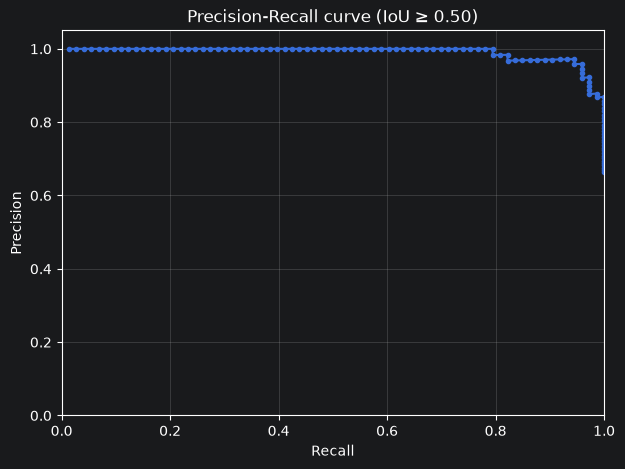

In [25]:
if metrics["precision_curve"]:
    plt.figure(figsize=(7, 5))
    plt.plot(metrics["recall_curve"], metrics["precision_curve"], marker=".")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"Precision-Recall curve (IoU ≥ {IOU_THRESHOLD:.2f})")
    plt.xlim(0, 1); plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.show()


### Metric protocol matters

Always report the IoU threshold, class set, AP interpolation method, and evaluation split. Do not call a one-class AP result “COCO mAP”. A benchmark-grade COCO evaluation should use the official COCO evaluator and a compatible annotation format.

## 16. NMS and prediction visualization

Non-Maximum Suppression removes redundant overlapping boxes. It sorts detections by score, keeps the highest-scoring box, removes boxes whose IoU with it exceeds a threshold, and repeats. TorchVision applies NMS internally in Faster R-CNN.

In [26]:
demo_boxes = torch.tensor([[10,10,80,90], [14,14,78,88], [100,20,160,100]], dtype=torch.float32)
demo_scores = torch.tensor([0.95, 0.80, 0.90])
keep = nms(demo_boxes, demo_scores, iou_threshold=0.5)
print("Kept indices:", keep.tolist())


Kept indices: [0, 2]


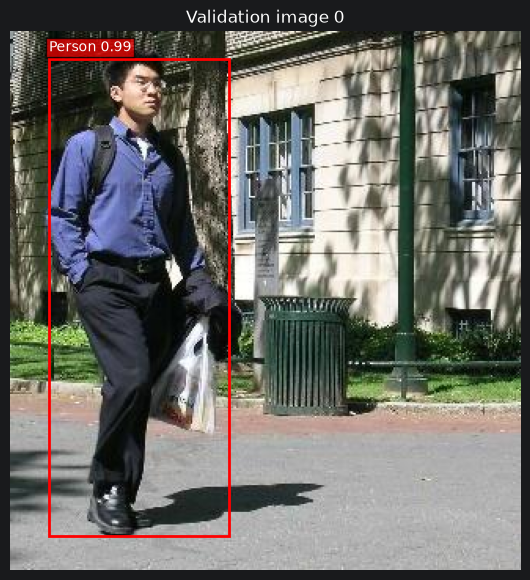

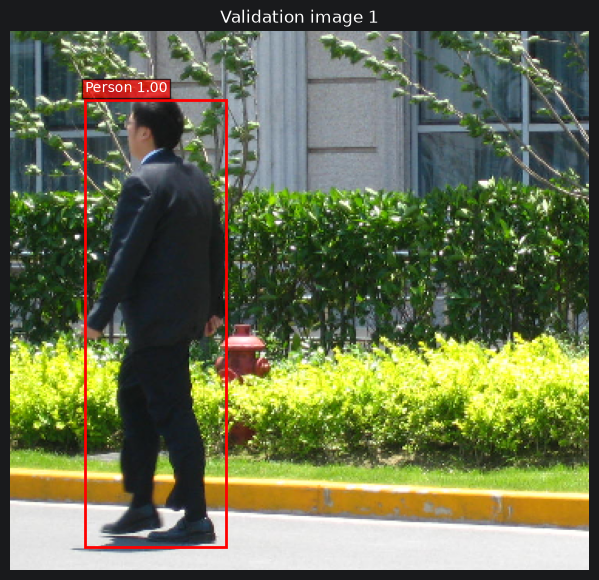

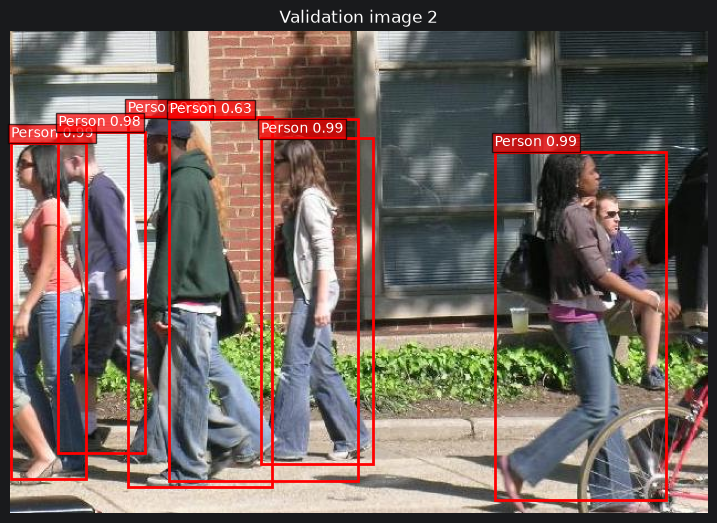

In [27]:
def visualize_predictions(image, prediction, score_threshold=0.5, title="Predictions"):
    array = image.permute(1, 2, 0).cpu().numpy()
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(array)
    keep = prediction["scores"] >= score_threshold
    for box, score in zip(prediction["boxes"][keep], prediction["scores"][keep]):
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                               fill=False, edgecolor="red", linewidth=2))
        ax.text(x1, max(0, y1-5), f"Person {score:.2f}", color="white",
                bbox=dict(facecolor="red", alpha=0.7, pad=2))
    ax.set_title(title); ax.axis("off"); plt.show()


model.eval()
for idx in range(min(3, len(val_set))):
    image, target = val_set[idx]
    with torch.no_grad():
        output = model([image.to(DEVICE)])[0]
    output = {k: v.cpu() for k, v in output.items()}
    visualize_predictions(image, output, SCORE_THRESHOLD, f"Validation image {idx}")


## 17. Error analysis

Inspect examples to identify:

- **False positive:** background incorrectly detected as a pedestrian.
- **False negative:** a real pedestrian is missed.
- **Localization error:** the predicted box overlaps the object poorly.
- **Duplicate detection:** multiple boxes correspond to one object.
- **Confidence calibration issue:** scores do not reflect empirical correctness.

Aggregate metrics cannot explain every failure. Always inspect predictions on representative examples.

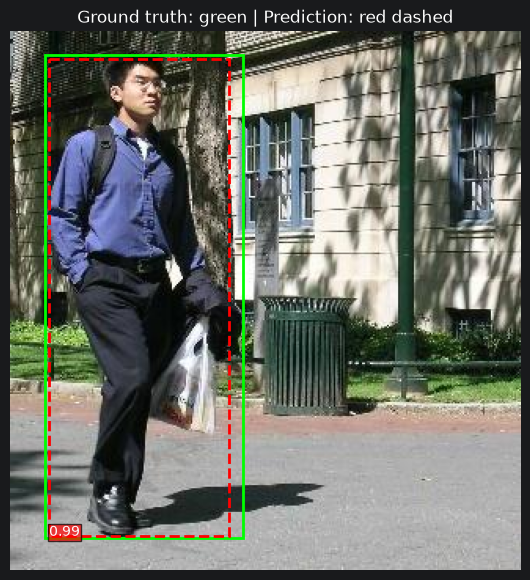

In [28]:
def compare_ground_truth_and_predictions(image, prediction, target, threshold=0.5):
    array = image.permute(1, 2, 0).cpu().numpy()
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(array)
    for box in target["boxes"]:
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(Rectangle((x1,y1), x2-x1, y2-y1, fill=False,
                               edgecolor="lime", linewidth=2))
    keep = prediction["scores"] >= threshold
    for box, score in zip(prediction["boxes"][keep], prediction["scores"][keep]):
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(Rectangle((x1,y1), x2-x1, y2-y1, fill=False,
                               edgecolor="red", linestyle="--", linewidth=2))
        ax.text(x1, y2, f"{score:.2f}", color="white",
                bbox=dict(facecolor="red", alpha=0.7, pad=1))
    ax.set_title("Ground truth: green | Prediction: red dashed")
    ax.axis("off"); plt.show()


image, target = val_set[0]
with torch.no_grad():
    prediction = model([image.to(DEVICE)])[0]
prediction = {k: v.cpu() for k, v in prediction.items()}
compare_ground_truth_and_predictions(image, prediction, target, SCORE_THRESHOLD)


## 18. Save and reload the model

A checkpoint stores model weights and metadata. Reconstruct the same architecture before loading its state dictionary.

In [29]:
checkpoint_path = OUTPUT_DIR / "fasterrcnn_pennfudan.pth"
torch.save({
    "model_state_dict": model.state_dict(),
    "num_classes": 2,
    "class_to_idx": {"background": 0, "person": 1},
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
}, checkpoint_path)
print("Saved:", checkpoint_path.resolve())


Saved: C:\Users\mobin\Downloads\outputs\fasterrcnn_pennfudan.pth


In [30]:
loaded_model = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None)
in_features = loaded_model.roi_heads.box_predictor.cls_score.in_features
loaded_model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.to(DEVICE).eval()
print("Model reloaded.")


C:\Users\mobin\AppData\Local\Temp\ipykernel_14624\3690992951.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=DEVICE

Model reloaded.


## 19. Inference on a new image

The model performs its configured resizing and normalization internally. Input images should be floating-point tensors in `[0,1]` with shape `[C,H,W]`.

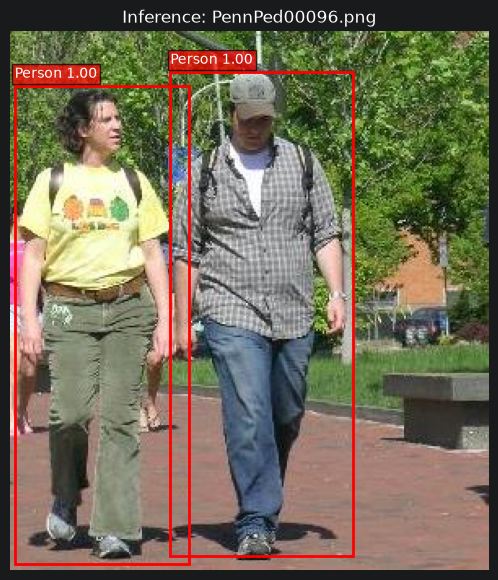

Detected pedestrians: 2


In [31]:
def predict_image(model, image_path, device, score_threshold=0.5):
    pil_image = Image.open(image_path).convert("RGB")
    tensor = T.ToTensor()(pil_image).to(device)
    model.eval()
    with torch.no_grad():
        output = model([tensor])[0]
    output = {k: v.detach().cpu() for k, v in output.items()}
    keep = output["scores"] >= score_threshold
    filtered = {k: v[keep] for k, v in output.items()}
    visualize_predictions(T.ToTensor()(pil_image), filtered, 0.0,
                          f"Inference: {Path(image_path).name}")
    return filtered


if image_paths:
    new_result = predict_image(loaded_model, image_paths[-1], DEVICE, SCORE_THRESHOLD)
    print("Detected pedestrians:", len(new_result["boxes"]))


## 20. Final review, limitations, and exercises

### What this project covered

- Dataset download and inspection.
- Instance-mask conversion to bounding boxes.
- Custom Dataset and detection DataLoader.
- Faster R-CNN fine-tuning.
- Loss tracking and visualization.
- IoU matching, precision, recall, and single-class AP.
- NMS, prediction visualization, and error analysis.
- Saving, loading, and inference.

### Limitations

Penn-Fudan is small and contains one object category. Results should not be assumed to generalize to arbitrary objects, camera systems, weather, or deployment settings. A stronger experiment should use a fixed held-out test set, multiple seeds, and a standard evaluator. The simple AP implementation above is educational and should not be presented as official COCO mAP.

### Exercises

1. Compare training with and without horizontal-flip augmentation.
2. Compare confidence thresholds 0.25, 0.50, and 0.75.
3. Visualize IoU for matched predictions.
4. Analyze recall for small and occluded pedestrians.
5. Add a separate untouched test set.
6. Implement COCO-style AP over IoU thresholds 0.50–0.95.
7. Compare Faster R-CNN with RetinaNet or SSD.
8. Record GPU memory use and epoch time for different batch sizes.

### References

1. PyTorch object-detection finetuning tutorial: https://pytorch.org/tutorials/intermediate/torchvision_tutorial.html
2. TorchVision detection models: https://pytorch.org/vision/stable/models.html
3. Ren et al. (2015), *Faster R-CNN*: https://arxiv.org/abs/1506.01497
4. Lin et al. (2017), *Feature Pyramid Networks*: https://arxiv.org/abs/1612.03144
5. Lin et al. (2014), *Microsoft COCO*: https://arxiv.org/abs/1405.0312

**End of Notebook 11 — Object Detection with PyTorch**
